# 03 生育模型：年龄曲线、进度效应与 TFR 贝叶斯预测

**这一步要回答的问题**：未来每年会有多少“发行量”（出生）？由两个部分决定——
1. **生育水平** TFR：平均每名妇女一生生几个孩子；
2. **生育时间** 年龄别生育率的形状：在哪个年龄生（平均生育年龄 MAC）。

旧模型的问题：TFR 用三个普查点做线性外推（结果是 TFR 会上升，与现实相反）；生育年龄模式固定为 2020 年不变。

本 notebook：
- 用 **Hadwiger 参数曲线** 描述年龄模式，看清“晚育”的趋势；
- 用 **Bongaarts–Feeney 进度调整** 区分“少生”和“晚生”；
- 用 **贝叶斯 AR(1) 模型** 预测 TFR 并给出概率区间（与联合国 BayesTFR 同一结构）；
- 用 **回测** 和 **先验敏感性分析** 检验这个预测到底有多可信。

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iop import census, coverage, ddm, fertility, leecarter, lifetable, official, wpp
from iop.plotting import COLORS, SEX_STYLE, YEAR_STYLE, fan, percentiles, pyramid, setup

setup()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

N_SIMS = 4000
SEED = 20261018
ind = wpp.indicators()

## 1. 三次普查的生育：谁在少生？

TFR 可以按孩次拆开：一孩总和生育率 + 二孩 + 三孩及以上。**一孩 TFR** 近似“最终有孩子的妇女比例”，
它的下降比总 TFR 更能说明问题——意味着不婚、不育的比例在上升。

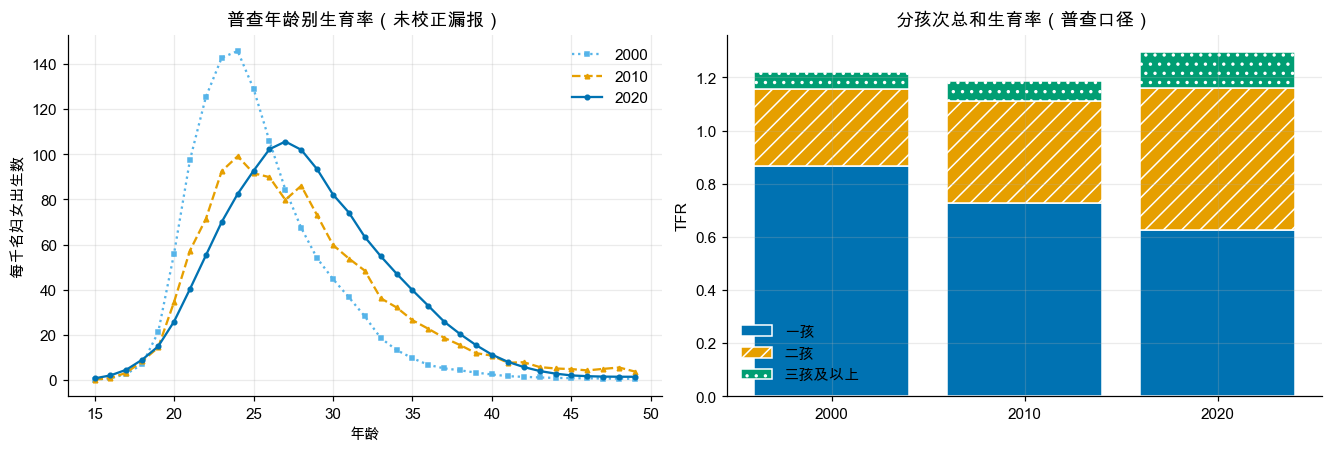

,一孩,二孩,三孩及以上,合计
2000,0.867,0.288,0.066,1.221
2010,0.728,0.381,0.079,1.188
2020,0.626,0.535,0.136,1.296


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
parity = {}
for year in census.YEARS:
    f = census.fertility(year)
    st = YEAR_STYLE[year]
    axes[0].plot(f.index, f["asfr"] * 1000, color=st["color"], ls=st["ls"], marker=st["marker"], ms=3, label=str(year))
    parity[year] = {"一孩": f["asfr1"].sum(), "二孩": f["asfr2"].sum(), "三孩及以上": f["asfr3"].sum()}
axes[0].set(title="普查年龄别生育率（未校正漏报）", xlabel="年龄", ylabel="每千名妇女出生数")
axes[0].legend()

parity = pd.DataFrame(parity).T
bottom = np.zeros(len(parity))
for col, color, hatch in zip(parity.columns, (COLORS["blue"], COLORS["orange"], COLORS["green"]), ("", "//", "..")):
    axes[1].bar(parity.index.astype(str), parity[col], bottom=bottom, color=color, hatch=hatch, edgecolor="white", label=col)
    bottom += parity[col].to_numpy()
axes[1].set(title="分孩次总和生育率（普查口径）", ylabel="TFR")
axes[1].legend()
plt.show()
parity.assign(合计=parity.sum(axis=1))

**读图**：
- 一孩 TFR 从 0.87 降到 0.63：若按 2020 年的水平持续，近四成妇女一生不生育（这是时期指标，含推迟效应，见第 4 节，不能直接等同于终身不育率）。
- 二孩 TFR 从 0.29 升到 0.54：主要是 2016 年“全面二孩”政策的补偿性生育，这部分**不可持续**——2017 年后出生数快速回落。
- 峰值生育年龄右移、曲线变矮变宽：晚育。

## 2. Hadwiger 曲线：用 3 个参数描述年龄模式

把 35 个年龄的生育率压缩成 3 个有含义的参数，便于比较和外推：
$$
f(x) = \frac{R\,H}{T\sqrt{\pi}} \left(\frac{T}{x}\right)^{3/2} \exp\!\left[-H^2\left(\frac{T}{x} + \frac{x}{T} - 2\right)\right]
$$
- $R$：曲线下面积 = TFR（**水平**）；
- $T$：位置参数，接近峰值年龄（**时间**）；
- $H$：集中度，越大越尖（**形状**）。

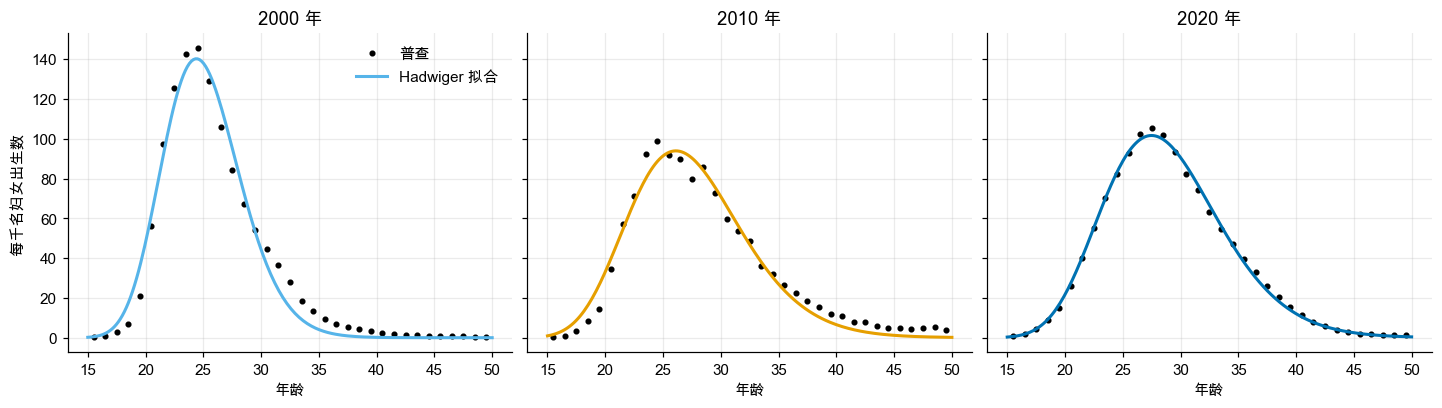

,R（TFR）,H（集中度）,T（位置）,平均生育年龄 MAC,R²
年份,,,,,
2000,1.176,5.194,25.091,25.870,0.980
2010,1.156,3.808,27.494,28.441,0.972
2020,1.292,3.880,28.892,28.976,0.998


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
rows = []
for ax, year in zip(axes, census.YEARS):
    f = census.fertility(year)
    x = f.index.to_numpy() + 0.5
    p = fertility.fit_hadwiger(x, f["asfr"].to_numpy())
    grid = np.linspace(15, 50, 200)
    ax.plot(x, f["asfr"] * 1000, "o", ms=3, color=COLORS["black"], label="普查")
    ax.plot(grid, fertility.hadwiger(grid, p["tfr"], p["h"], p["t"]) * 1000, color=YEAR_STYLE[year]["color"], lw=2, label="Hadwiger 拟合")
    ax.set(title=f"{year} 年", xlabel="年龄")
    rows.append({"年份": year, "R（TFR）": p["tfr"], "H（集中度）": p["h"], "T（位置）": p["t"],
                 "平均生育年龄 MAC": fertility.mean_age(x, f["asfr"].to_numpy()), "R²": p["r2"]})
axes[0].set_ylabel("每千名妇女出生数")
axes[0].legend()
plt.show()
hadwiger_params = pd.DataFrame(rows).set_index("年份")
hadwiger_params

三个参数就能解释 97% 以上的年龄变化。平均生育年龄 20 年推迟了约 3 岁。

## 3. 长时间序列：WPP 1950–2023

三次普查只有 3 个点，无法做时间序列建模。下面用 WPP 逐年估计（其 2000、2010 年水平高于普查原始值，与 notebook 01 的漏报校正方向一致）：

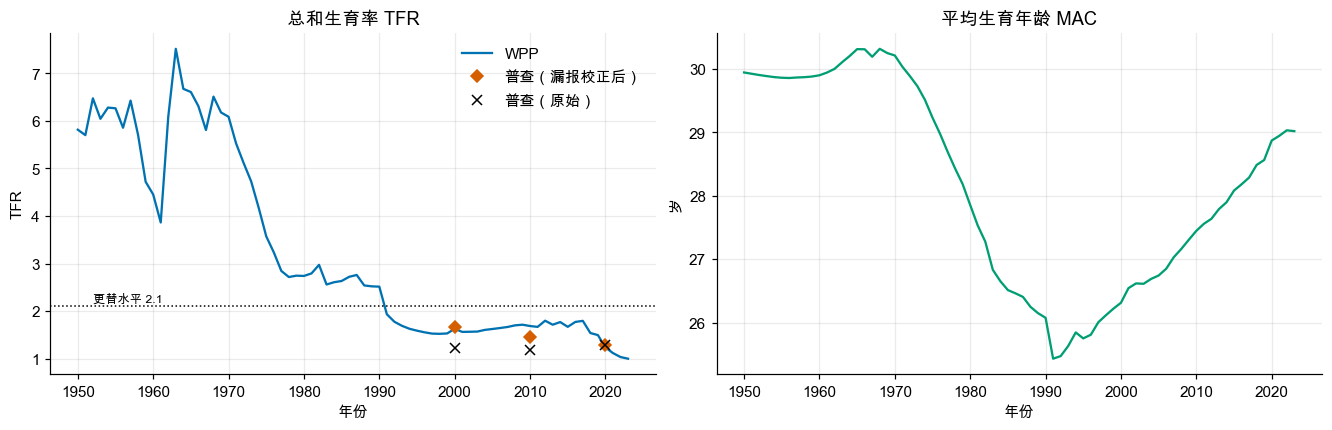

In [4]:
tfr_hist = ind["TFR"].loc[1950:2023]
mac_hist = ind["MAC"].loc[1950:2023]
adj_tfr = {y: coverage.fertility_coverage(y)["tfr_adjusted"] for y in census.YEARS}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(tfr_hist.index, tfr_hist, color=COLORS["blue"], label="WPP")
axes[0].plot(list(adj_tfr), list(adj_tfr.values()), "D", color=COLORS["vermillion"], label="普查（漏报校正后）")
axes[0].plot(list(census.YEARS), [census.tfr(y) for y in census.YEARS], "x", color=COLORS["black"], label="普查（原始）")
axes[0].axhline(2.1, color=COLORS["black"], ls=":", lw=1)
axes[0].text(1952, 2.2, "更替水平 2.1", fontsize=8)
axes[0].set(title="总和生育率 TFR", xlabel="年份", ylabel="TFR")
axes[0].legend()
axes[1].plot(mac_hist.index, mac_hist, color=COLORS["green"])
axes[1].set(title="平均生育年龄 MAC", xlabel="年份", ylabel="岁")
plt.show()

## 4. 进度效应：少生，还是晚生？

如果所有人都把生育推迟一年，那推迟的这一年里出生数会下降，当年 TFR 被“压低”，但每个人一生生的孩子数并没有变。
Bongaarts & Feeney (1998) 的调整：
$$
\text{TFR}^*_t = \frac{\text{TFR}_t}{1 - r_t}, \qquad r_t = \text{平均生育年龄的年变化}
$$
$\text{TFR}^*$ 估计“如果不推迟，生育水平是多少”。两条线之间的差就是**推迟造成的“暂时性”下降**。

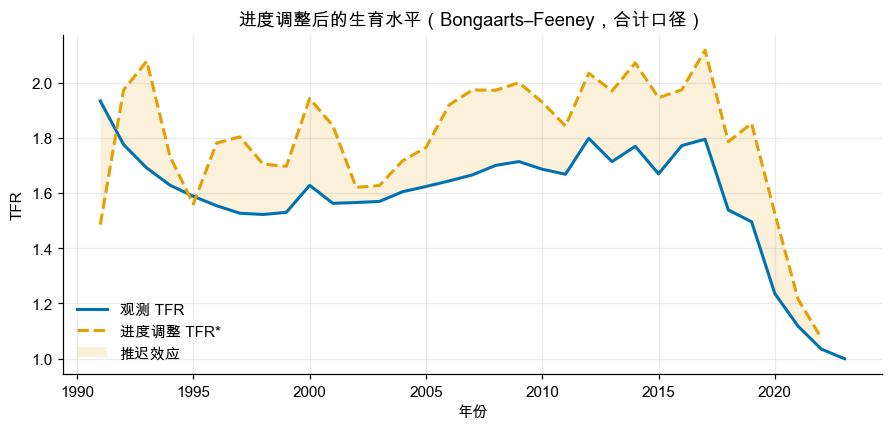

,TFR,MAC,TFR*
year,,,
2000,1.628,26.312,1.943
2005,1.624,26.742,1.765
2010,1.687,27.446,1.930
2015,1.670,28.081,1.946
2019,1.496,28.563,1.853
2021,1.117,28.944,1.215
2022,1.034,29.031,1.074


In [5]:
tempo = fertility.tempo_adjusted_tfr(tfr_hist, mac_hist).loc[1991:2022]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(tfr_hist.loc[1991:2023].index, tfr_hist.loc[1991:2023], color=COLORS["blue"], lw=2, label="观测 TFR")
ax.plot(tempo.index, tempo, color=COLORS["orange"], ls="--", lw=2, label="进度调整 TFR*")
ax.fill_between(tempo.index, tfr_hist.loc[tempo.index], tempo, color=COLORS["orange"], alpha=0.15, lw=0, label="推迟效应")
ax.set(title="进度调整后的生育水平（Bongaarts–Feeney，合计口径）", xlabel="年份", ylabel="TFR")
ax.legend()
plt.show()
pd.DataFrame({"TFR": tfr_hist, "MAC": mac_hist, "TFR*": tempo}).loc[[2000, 2005, 2010, 2015, 2019, 2021, 2022]]

**读图**：
- 2000–2019 年，推迟效应让观测 TFR 比不推迟时的水平低约 0.15–0.35（逐年值波动较大，应看趋势而非单年）。
- 但 2020 年以后两条线一起下跌——**下降不再只是推迟，而是“少生”**。这是比 TFR 数值本身更重要的结论：
  如果只是推迟，等推迟结束 TFR 会自然回升；现在的证据不支持这种乐观预期。

局限：严格的做法应按孩次分别调整再相加，这里因缺少逐年分孩次数据只做了合计版本，结果偏粗。

## 5. 平均生育年龄的未来：情景参数

用 logistic 曲线描述 MAC 逐渐趋向一个上限。但只用中国 1991–2023 年数据，**上限无法从数据中识别**（拟合会顶到任意设定的边界），
所以上限作为情景参数，参照东亚低生育社会：日本约 32 岁，韩国约 33 岁。

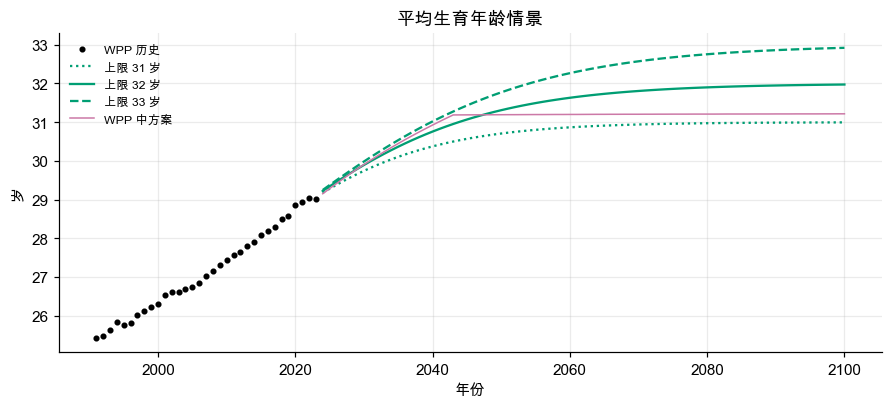

In [6]:
mac_trends = {u: fertility.fit_mac_trend(mac_hist.loc[1991:2023], u) for u in (31, 32, 33)}
future = np.arange(2024, 2101)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(mac_hist.loc[1991:].index, mac_hist.loc[1991:], "o", ms=3, color=COLORS["black"], label="WPP 历史")
for (u, tr), ls in zip(mac_trends.items(), (":", "-", "--")):
    proj = fertility.project_mac(tr, future)
    ax.plot(proj.index, proj, ls=ls, color=COLORS["green"], label=f"上限 {u} 岁")
ax.plot(ind["MAC"].loc[2024:2100].index, ind["MAC"].loc[2024:2100], color=COLORS["purple"], lw=1, label="WPP 中方案")
ax.set(title="平均生育年龄情景", xlabel="年份", ylabel="岁")
ax.legend(fontsize=8)
plt.show()

## 6. TFR 的贝叶斯 AR(1) 预测

### 模型
对 $y_t = \log \text{TFR}_t$：
$$
y_t - \mu = \rho\,(y_{t-1} - \mu) + \varepsilon_t, \qquad \varepsilon_t \sim N(0, \sigma^2)
$$
- $\mu$：长期均衡水平（TFR 最终会围绕 $e^\mu$ 波动）；
- $\rho$：回归速度。$\rho=1$ 是随机游走（永远不回归），$\rho$ 越小回归越快；
- $\sigma$：每年的随机冲击。

这正是联合国 WPP 用的 BayesTFR “第三阶段”模型结构。联合国用全球各国数据做分层先验，这里只有中国一国，所以**先验要显式写出来**：
- $\mu$：TFR 中位数 1.3（东亚低生育社会经验），对数尺度标准差 0.25（95% 先验区间约 0.8–2.1）；
- $\rho$：在 [0.5, 1] 上均匀；
- $\sigma^2$：无信息先验 $p(\sigma^2) \propto 1/\sigma^2$，可以解析积分掉。

### 为什么用贝叶斯？
数据只有 33 年，而且一直在下降，**单靠数据无法确定长期均衡**。贝叶斯方法把“东亚经验”作为先验明确写出来，
后验 = 先验 × 数据证据，然后用**敏感性分析**展示：换一个先验，结论变多少。这比线性外推或只给一条曲线诚实得多。

### 计算
$(\mu, \rho)$ 只有两个参数，所以直接在 241 × 201 的网格上精确计算后验，不需要 MCMC：
$$
p(\mu, \rho \mid y) \propto p(\mu)\,p(\rho)\cdot \text{SSR}(\mu, \rho)^{-n/2}
$$

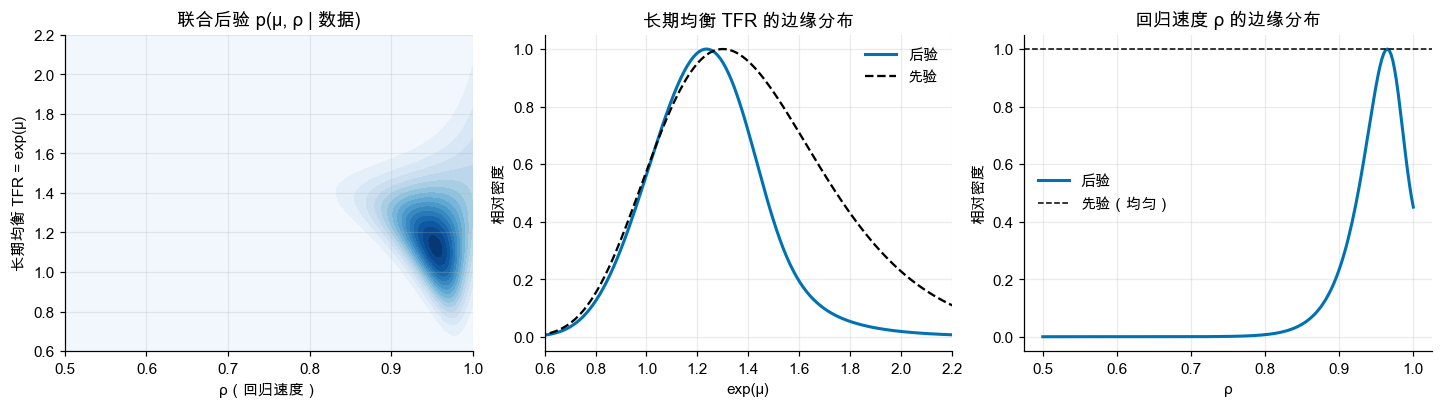

,后验均值,2.5%,97.5%
长期均衡 TFR,1.200,0.788,1.669
ρ,0.949,0.863,0.998


In [7]:
TRAIN = tfr_hist.loc[1991:2023]
post = fertility.fit_tfr_ar1(TRAIN)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
W = post.weights
axes[0].contourf(post.rho_grid, np.exp(post.mu_grid), W, levels=15, cmap="Blues")
axes[0].set(title="联合后验 p(μ, ρ | 数据)", xlabel="ρ（回归速度）", ylabel="长期均衡 TFR = exp(μ)", ylim=(0.6, 2.2))
mu_m = post.marginal_mu()
prior_mu = np.exp(-0.5 * ((post.mu_grid - np.log(post.prior.median)) / post.prior.log_sd) ** 2)
axes[1].plot(mu_m.index, mu_m / mu_m.max(), color=COLORS["blue"], lw=2, label="后验")
axes[1].plot(mu_m.index, prior_mu / prior_mu.max(), color=COLORS["black"], ls="--", label="先验")
axes[1].set(title="长期均衡 TFR 的边缘分布", xlabel="exp(μ)", ylabel="相对密度", xlim=(0.6, 2.2))
axes[1].legend()
rho_m = post.marginal_rho()
axes[2].plot(rho_m.index, rho_m / rho_m.max(), color=COLORS["blue"], lw=2, label="后验")
axes[2].axhline(1.0, color=COLORS["black"], ls="--", lw=1, label="先验（均匀）")
axes[2].set(title="回归速度 ρ 的边缘分布", xlabel="ρ", ylabel="相对密度")
axes[2].legend()
plt.show()

def summarize(s):
    s = s / s.sum()
    m = (s.index * s).sum()
    cdf = s.cumsum()
    return {"后验均值": m, "2.5%": s.index[np.searchsorted(cdf, 0.025)], "97.5%": s.index[np.searchsorted(cdf, 0.975)]}
pd.DataFrame({"长期均衡 TFR": summarize(mu_m), "ρ": summarize(rho_m)}).T

**读图**：
- $\rho$ 的后验均值约 0.95，95% 区间约 0.86–1.0，而且贴着上界 1：数据本身几乎无法排除“随机游走、永不回归”。
  TFR 的变化非常“粘”，偏离均衡后要很多年才回归（$\rho=0.95$ 时，偏离的一半要约 14 年才消失）。
- 长期均衡 TFR 的后验比先验稍偏低并变窄——数据把它往下拉了一些，但**主要信息仍来自先验**。这一点必须在汇报中明说。

### 预测与联合国对比

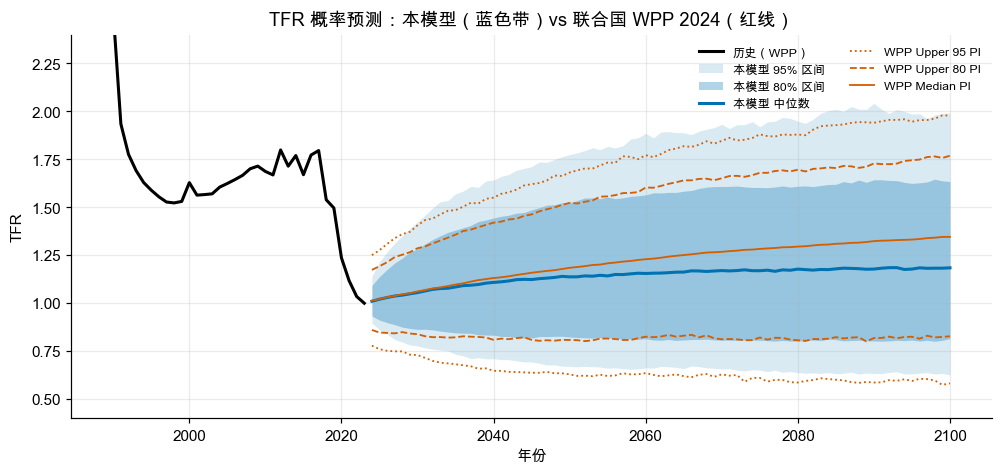

,本模型 2.5%,本模型 中位,本模型 97.5%,WPP 2.5%,WPP 中位,WPP 97.5%
2030,0.776,1.055,1.423,0.729,1.061,1.406
2050,0.669,1.137,1.774,0.629,1.184,1.681
2070,0.656,1.170,1.932,0.628,1.267,1.846
2100,0.626,1.184,1.991,0.582,1.345,1.978


In [8]:
H = 2100 - 2023
paths = fertility.simulate_tfr(post, H, N_SIMS, seed=SEED)
f_tfr = fertility.fan(paths)

wpp_pi = {v: wpp.tfr_from_asfr5(v).loc[2024:2100] for v in ("Lower 95 PI", "Lower 80 PI", "Median PI", "Upper 80 PI", "Upper 95 PI")}
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(tfr_hist.loc[1990:].index, tfr_hist.loc[1990:], color=COLORS["black"], lw=2, label="历史（WPP）")
fan(ax, f_tfr, COLORS["blue"], "本模型")
for v, ls in (("Lower 95 PI", ":"), ("Upper 95 PI", ":"), ("Lower 80 PI", "--"), ("Upper 80 PI", "--"), ("Median PI", "-")):
    ax.plot(wpp_pi[v].index, wpp_pi[v], color=COLORS["vermillion"], ls=ls, lw=1.2, label=f"WPP {v}" if v in ("Median PI", "Upper 95 PI", "Upper 80 PI") else None)
ax.set(title="TFR 概率预测：本模型（蓝色带）vs 联合国 WPP 2024（红线）", xlabel="年份", ylabel="TFR", ylim=(0.4, 2.4))
ax.legend(fontsize=8, ncol=2, loc="upper right")
plt.show()

cmp = pd.DataFrame({
    "本模型 2.5%": f_tfr["p2.5"], "本模型 中位": f_tfr["p50"], "本模型 97.5%": f_tfr["p97.5"],
    "WPP 2.5%": wpp_pi["Lower 95 PI"], "WPP 中位": wpp_pi["Median PI"], "WPP 97.5%": wpp_pi["Upper 95 PI"],
}).loc[[2030, 2050, 2070, 2100]]
cmp

本模型与联合国的方法完全独立实现、只用中国一国数据，但 95% 区间与 WPP 非常接近——说明结果不是某个参数设定的偶然产物。

### 先验敏感性：换一个先验，结论变多少？

In [9]:
rows = []
for label, prior in {
    "悲观：均衡中位 1.0": fertility.TfrPrior(median=1.0),
    "基准：均衡中位 1.3": fertility.TfrPrior(median=1.3),
    "乐观：均衡中位 1.6": fertility.TfrPrior(median=1.6),
    "宽先验：中位 1.3，sd 0.5": fertility.TfrPrior(median=1.3, log_sd=0.5),
    "限制 ρ ≤ 0.95": fertility.TfrPrior(rho_hi=0.95),
}.items():
    p = fertility.fit_tfr_ar1(TRAIN, prior)
    fn = fertility.fan(fertility.simulate_tfr(p, H, 2000, seed=SEED))
    rows.append({"先验": label, "2030 中位": fn.loc[2030, "p50"], "2050 中位": fn.loc[2050, "p50"], "2050 95%区间": f"{fn.loc[2050, 'p2.5']:.2f}–{fn.loc[2050, 'p97.5']:.2f}",
                 "2100 中位": fn.loc[2100, "p50"], "2100 95%区间": f"{fn.loc[2100, 'p2.5']:.2f}–{fn.loc[2100, 'p97.5']:.2f}"})
pd.DataFrame(rows).set_index("先验")

,2030 中位,2050 中位,2050 95%区间,2100 中位,2100 95%区间
先验,,,,,
悲观：均衡中位 1.0,1.013,1.020,0.62–1.64,1.031,0.55–1.80
基准：均衡中位 1.3,1.055,1.135,0.67–1.77,1.187,0.63–1.99
乐观：均衡中位 1.6,1.078,1.199,0.68–1.84,1.278,0.68–2.29
宽先验：中位 1.3，sd 0.5,1.023,1.054,0.59–1.73,1.079,0.53–1.98
限制 ρ ≤ 0.95,1.108,1.210,0.79–1.77,1.246,0.80–1.84


**读表**：
- 2030 年各先验的中位数只差约 0.1：近期走势主要由当前水平决定（$\rho$ 接近 1），数据主导。
- 2050、2100 年中位数随先验相差约 0.2–0.25，而且“限制 $\rho \le 0.95$”的影响和换均衡先验一样大：长期结果取决于两个数据无法确定的假设——均衡水平在哪、回归有多快。
- **所以：10 年左右的预测是数据驱动的，几十年以上的预测本质上是情景假设**——这对“超长期债券”的解读至关重要，汇报时要把长期结论表述为“在某某假设下”。

### 回测：站在 2012 年能预见后来的下跌吗？

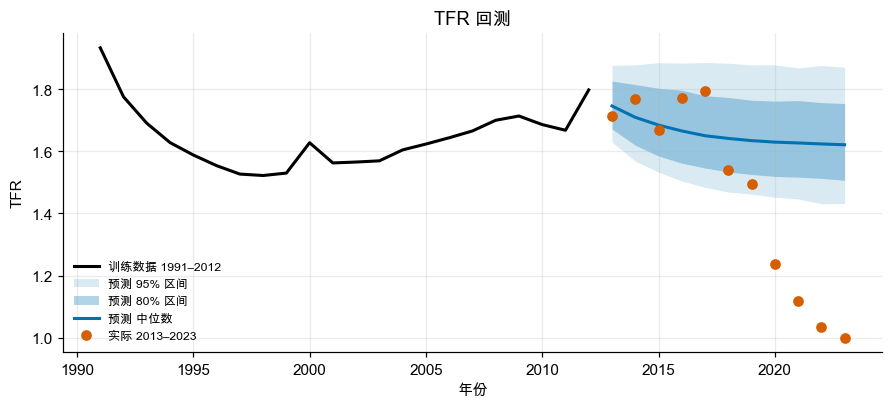

落入 95% 区间：7/11 年；跌出区间的年份：[2020, 2021, 2022, 2023]


In [10]:
post_bt = fertility.fit_tfr_ar1(tfr_hist.loc[1991:2012])
fn_bt = fertility.fan(fertility.simulate_tfr(post_bt, 11, N_SIMS, seed=SEED))
actual = tfr_hist.loc[2013:2023]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(tfr_hist.loc[1991:2012].index, tfr_hist.loc[1991:2012], color=COLORS["black"], lw=2, label="训练数据 1991–2012")
fan(ax, fn_bt, COLORS["blue"], "预测")
ax.plot(actual.index, actual, "o", color=COLORS["vermillion"], label="实际 2013–2023")
ax.set(title="TFR 回测", xlabel="年份", ylabel="TFR")
ax.legend(fontsize=8)
plt.show()
inside = (actual >= fn_bt["p2.5"]) & (actual <= fn_bt["p97.5"])
print(f"落入 95% 区间：{inside.sum()}/{len(inside)} 年；跌出区间的年份：{list(actual.index[~inside])}")

**读图**：2013–2019 年在区间内；**2020 年之后的骤降完全落在 95% 区间之外**。当时的主流预测也普遍没有预见到这样幅度的下跌。
原因是这段下跌由模型之外的结构性因素驱动：二孩政策的提前释放、婚姻推迟、房价与教育成本、新冠冲击。

**这是本 notebook 最重要的方法论结论**：统计模型给出的预测区间只覆盖“正常年份的随机波动”，不覆盖结构性冲击。
所以在人口债券模型中，TFR 必须**同时**使用：
1. 概率预测（本节的扇形图）——描述常规不确定性；
2. 情景分析（例如持续 0.8 的“韩国情景”、回升到 1.5 的“政策见效情景”）——描述结构性风险。

## 7. 合成未来的年龄别生育率

把三个部件拼起来：**TFR 路径 × MAC 情景 × 2020 年普查的形状参数 $H$**，就得到每年单岁的生育率，供下一阶段的人口预测使用。

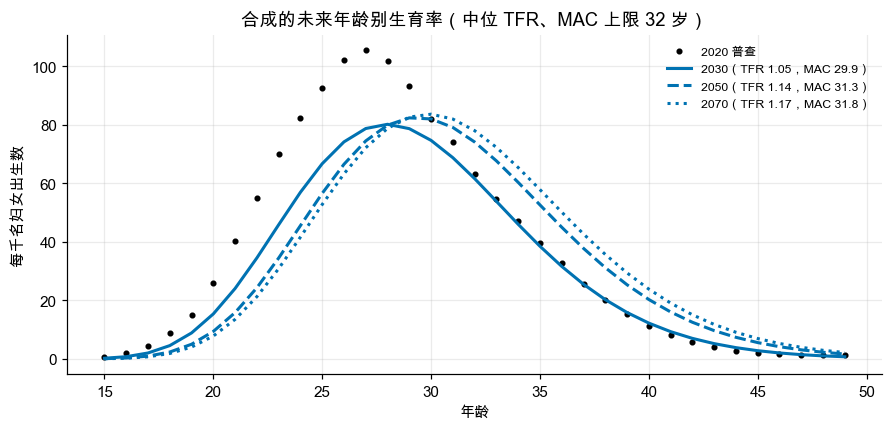

In [11]:
h_2020 = hadwiger_params.loc[2020, "H（集中度）"]
mac_mid = fertility.project_mac(mac_trends[32], future)
fig, ax = plt.subplots(figsize=(8, 3.8))
f20 = census.fertility(2020)
ax.plot(f20.index, f20["asfr"] * 1000, "o", ms=3, color=COLORS["black"], label="2020 普查")
for year, ls in zip((2030, 2050, 2070), ("-", "--", ":")):
    sched = fertility.schedule(f_tfr.loc[year, "p50"], mac_mid.loc[year], h_2020)
    ax.plot(sched.index, sched * 1000, ls=ls, lw=2, color=COLORS["blue"], label=f"{year}（TFR {f_tfr.loc[year, 'p50']:.2f}，MAC {mac_mid.loc[year]:.1f}）")
ax.set(title="合成的未来年龄别生育率（中位 TFR、MAC 上限 32 岁）", xlabel="年龄", ylabel="每千名妇女出生数")
ax.legend(fontsize=8)
plt.show()

## 小结

| 环节 | 旧模型 | 新模型 |
|---|---|---|
| TFR 水平 | 普查原始值（2000、2010 年低估约 20%–27%） | 官方出生数校准 + WPP 长序列 |
| TFR 预测 | 三点线性外推（向上） | 贝叶斯 AR(1)，4000 条路径，先验敏感性分析 |
| 年龄模式 | 固定 2020 年 | Hadwiger 曲线，MAC 按情景继续推迟 |
| 少生 vs 晚生 | 未区分 | Bongaarts–Feeney 进度调整 |
| 可信度 | 无检验 | 回测 + 与联合国独立对比 |

> **对导师怎么说**：生育模块分三层。第一，用 Hadwiger 曲线和进度调整说明，2020 年以前的低 TFR 有相当部分是“晚生”，
> 但 2020 年之后进度调整后的 TFR 同步下跌，说明已转为“少生”，一孩 TFR 降到 0.63 是关键信号。
> 第二，用与联合国 BayesTFR 同结构的贝叶斯 AR(1) 模型做概率预测，95% 区间与 WPP 2024 独立结果高度一致；先验敏感性分析显示，
> 10 年左右的预测由数据主导，几十年以上则由长期均衡和回归速度的假设主导。第三，回测表明统计区间无法覆盖 2020 年后的结构性骤降，
> 因此下一阶段的人口债券预测将同时报告概率区间与结构性情景。

**下一步（阶段 3）**：把 notebook 01–03 的三个部件接入队列要素人口预测，对 2021–2100 年做蒙特卡洛模拟，
得到出生（发行）、20 岁人口（入场）、65 岁以上人口（兑付）的概率分布，并重新计算人口债券指标。